# COS30082 A-ML
# Lab 4. Convolutional Neural Network (CNN)
---

# Lab/Tutorial
## 1. Study: Overfitting and Underfitting  
It is important to be able to identify overfitting and underfitting, especially overfitting problems when your model cannot generalize well with unseen test data due to the small size and lack of diversity in the data sets. Transfer learning is one of the frequently used approaches to reduce overfitting, We will examine transfer learning next week. In this lab, we will explore several common regularization techniques, and use them to improve a classification model.  

Study the TensorFlow tutorial in the following link: [Overfit and underfit](https://www.tensorflow.org/tutorials/keras/overfit_and_underfit).

## 2. Study: Convolutional Neural Network (CNN)  
Study the TensorFlow tutorial in the link below. This tutorial demonstrates how to train a simple Convolutional Neural Network (CNN) to classify CIFAR images.

[Convolutional Neural Network (CNN) - TensorFlow](https://www.tensorflow.org/tutorials/images/cnn)

## 3. Lab Task
Submit your work to Canvas and demonstrate your work to the tutor during the lab session.

---

# Lab_04_CNN.pdf (Extracted)
## 0. Dataset
Use the Intel Image Classification dataset. [Intel Image Classification - Image Scene Classification of Multiclass](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)

The dataset contains natural scene images belonging to six classes:
- buildings
- forest
- glacier
- mountain
- sea
- street

Use the seg_train and seg_test folders. The seg_pred folder is not required.
Use the seg_train dataset for training. Split it into training (80%) and validation (20%) sets.
After training the model, evaluate its performance using the seg_test dataset.

## 1. Dataset Preparation
Prepare the dataset, including:
1. Load the dataset.
2. Resize images to 150 × 150 if they are not already 150 × 150.
3. Normalize pixel values to [0,1].
4. Split the seg_train dataset into training and validation datasets.
Display several example images from the dataset and report:
- Number of training samples
- Number of validation samples
- Number of test samples
- Number of classes

## 2. Build a CNN Model
Build a Convolutional Neural Network. The network must include at least:
- 1 Conv2D layer
- 1 MaxPooling layer
- 1 Flatten layer
- 1 Dense layer
Train the model. Report the test accuracy on the seg_test dataset.

## 3. Modify the CNN Architecture
Modify the CNN architecture. For example, you may:
- Add additional Conv2D layers
- Add additional MaxPooling layers
- Change the number of filters
Train the model. Report the test accuracy on the seg_test dataset.

## 4. Data Augmentation
Apply data augmentation to the training dataset only. For example:
- horizontal flip
- rotation
- zoom
- brightness adjustment
Train the model. Report the test accuracy on the seg_test dataset.

## 5. Regularization
Apply regularization techniques such as Dropout layers or EarlyStopping during training. Train the
model. Report the test accuracy on the seg_test dataset.

## 6. Report
Create a short report (1 page) including:
1. Model architecture diagrams
2. Training settings (e.g., epochs, optimizer, loss function)
3. Data augmentation methods used
4. Regularization methods used
5. Compare the test accuracy of the models in Tasks 2 to 5.

##Submission
Submit your source code and report to Canvas and demonstrate your work to the tutor during the
lab session.

---

# 0. Introduction

In this lab, we will develop a Convolutional Neural Network (CNN) to classify natural scene images using the Intel Image Classification dataset.

The dataset contains six image classes: buildings, forest, glacier, mountain, sea, and street. Since the data consists of JPG images organized into class-specific folders, we can use TensorFlow/Keras to load the images and obtain their labels directly from the folder names.

We will begin by preparing the dataset and building a basic CNN. We will then modify the network architecture, apply data augmentation, and introduce regularization techniques to investigate how these changes affect model performance and generalization.

Finally, we will evaluate the models using the test dataset and compare their test accuracy.

## 0.1 Learning Objectives

By the end of this lab, we aim to:

1. Load and prepare an image-classification dataset.
2. Resize images to 150 × 150 pixels and normalize pixel values to the range [0, 1].
3. Split the training dataset into training and validation sets using an 80:20 ratio.
4. Build and train a basic Convolutional Neural Network.
5. Modify the CNN architecture and compare model performance.
6. Apply data augmentation to training images.
7. Apply regularization techniques to help reduce overfitting.
8. Evaluate and compare the models using test accuracy.
9. Communicate the experimental results in a short report.

## Part 1: Environment and library setup
Before we load any images, we prepare the Python environment.

### 1.1 Lecture: What is a library?
A library is a collection of ready-made code that we import instead of writing ourselves. In earlier labs we used Pandas to inspect tabular data and Matplotlib to visualize results. For this lab we add TensorFlow/Keras, which can load image folders and build and train neural networks.

| Library | Purpose in this lab |
|---|---|
| `os` | Work with folder paths and inspect the dataset structure |
| `pathlib.Path` | Manage file and folder paths in a cleaner way than plain text |
| `numpy` | Handle numerical arrays |
| `matplotlib.pyplot` | Display images and plot training results |
| `pandas` | Build the results tables that compare the models |
| `tensorflow` | Load image datasets, build and train CNNs |
| `tf.keras` (inside tensorflow) | Layers, loss functions and training for the CNN |

`import numpy as np` loads a library under a short nickname, so we can write `np.array(...)` instead of `numpy.array(...)`. The nicknames `np`, `plt` and `tf` are standard, and almost every tutorial uses them.

We do not install libraries every time we open the notebook. Most of them are already in the environment, so the first step is to check that TensorFlow is available.

In [1]:
import os                          # folder and file operations
from pathlib import Path           # cleaner way to handle file paths

import numpy as np                 # numerical arrays
import matplotlib.pyplot as plt    # plots and image display
import pandas as pd                # results tables
import tensorflow as tf            # neural networks (Keras is inside it)

# Display the installed TensorFlow version
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### 1.2 Is a GPU available?
A convolution layer repeats the same small calculation across every position of every image. A CPU does these a few at a time, while a GPU does thousands at once. Training a CNN on a CPU still works, it is just slower, so if no GPU is found we will plan the number of epochs around that.

In [2]:
# Check GPU availability

gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs:", gpus)

if gpus:
    print("GPU is available for training.")
else:
    print("WARNING: No GPU detected.")

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU is available for training.


**Reading the result**

- If a GPU is detected, TensorFlow can potentially use it to accelerate model training.
- If no GPU is detected, the notebook can still run using the CPU, although training may take longer.
- In Google Colab, check **Runtime → Change runtime type** if you want to request a GPU.
- On Windows, GPU support depends on the TensorFlow version and environment. Native Windows support differs from WSL2 and other supported configurations.

A GPU is helpful but is not a requirement for this lab. We can begin with a modest CNN and adjust the training workload to suit the available hardware.

### 1.3 Configure and Verify the Dataset Paths

The Intel Image Classification dataset contains three folders: `seg_train`, `seg_test`, and `seg_pred`.

The location of these folders depends on the execution environment. In Google Colab, we can access the dataset through Google Drive. In local environments such as VS Code or Anaconda, we can access folders stored on the computer.

We will configure the dataset location once and verify that the training and testing folders exist before loading the images.

In [3]:
# Section 1.3: Configure and verify dataset paths

from pathlib import Path

# Detect whether the notebook is running in Google Colab
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Configure the dataset's parent folder
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    dataset_path = Path("/content/drive/MyDrive/COS30082/Lab04")
else:
    # Change this to your dataset's location when running locally
    dataset_path = Path.cwd()

# Define the dataset folders
train_dir = dataset_path / "seg_train"
test_dir = dataset_path / "seg_test"
pred_dir = dataset_path / "seg_pred"

# Display the paths being checked
print("Environment:", "Google Colab" if IN_COLAB else "Local Python")
print("Dataset location:", dataset_path)
print("Training folder exists:", train_dir.is_dir())
print("Testing folder exists:", test_dir.is_dir())
print("Prediction folder exists:", pred_dir.is_dir())

# Show the actual contents of the dataset directory
print("\nContents of dataset directory:")
if dataset_path.is_dir():
    for item in sorted(dataset_path.iterdir()):
        print(" -", item.name)
else:
    print("Dataset directory itself does not exist.")

# Stop early, with a clear message, if the folders are missing
if not (train_dir.is_dir() and test_dir.is_dir()):
    raise FileNotFoundError("seg_train or seg_test not found. Check dataset_path above.")

Mounted at /content/drive
Environment: Google Colab
Dataset location: /content/drive/MyDrive/COS30082/Lab04
Training folder exists: True
Testing folder exists: True
Prediction folder exists: True

Contents of dataset directory:
 - intel_data.zip
 - seg_pred
 - seg_test
 - seg_train


### Optional Optimization: Faster Dataset Loading

**Purpose:** Reduce data-loading overhead when training in Google Colab.

The dataset is stored in a ZIP file `intel_data.zip` containing only `seg_train` and `seg_test`. When running in Colab (or other apps), the following cell extracts the dataset to `/content/intel_local`, allowing image files to be accessed from local storage rather than repeatedly read from Google Drive.

This optimization does not change the dataset, CNN architecture, or training parameters. Skip this step when running locally or when the dataset is already stored on local disk.

In [4]:
# This cell use to help Epochs run faster
# Speed-up: on Colab, unpack the dataset from one zip file onto Colab's local disk.
# "intel_data.zip" only contains "seg_train" and "seg_test"
import shutil
import zipfile

zip_path = dataset_path / "intel_data.zip"
local_root = Path("/content/intel_local")

if IN_COLAB and zip_path.exists():
    # Copy the single zip file, then unpack it (done only once per session)
    if not (local_root / "seg_train").exists():
        shutil.copy(zip_path, "/content/intel_data.zip")
        with zipfile.ZipFile("/content/intel_data.zip") as z:
            z.extractall(local_root)

    train_dir = local_root / "seg_train"
    test_dir = local_root / "seg_test"
    print("Using the fast local copy.")
else:
    print("Using the original folders.")

if not (train_dir.is_dir() and test_dir.is_dir()):
    raise FileNotFoundError("seg_train / seg_test not found. Check the zip contents.")

print("Training folder:", train_dir)
print("Testing folder :", test_dir)

Using the fast local copy.
Training folder: /content/intel_local/seg_train
Testing folder : /content/intel_local/seg_test


## Part 2: Dataset Exploration and Preparation

### 2.1 Introduction:
Before building a Convolutional Neural Network (CNN), we need to understand the dataset and prepare the images for training.

In this section, we will:

- Inspect the image-class folders and identify the six classes.
- Count the images in each class.
- Display sample images to understand what the model will learn from.
- Resize images to 150 × 150 pixels.
- Normalize pixel values to the range [0, 1].
- Split the training dataset into 80% training and 20% validation data.
- Keep the test dataset separate for final model evaluation.

**Why is this important?** A model's performance depends not only on its architecture but also on the quality and preparation of its input data

### 2.2 Inspect the Class Folders

The Intel Image Classification dataset contains six image classes:

- `buildings`
- `forest`
- `glacier`
- `mountain`
- `sea`
- `street`

Each class is stored in its own folder. We will inspect the folder names in both `seg_train` and `seg_test` to confirm that the training and testing datasets contain the same classes.

**Important:** Before running this cell, make sure `train_dir` and `test_dir` were correctly defined in Part 1.

In [5]:
# Part 2.2: Inspect the class folders

# Get the class folder names from the training directory
class_names = sorted([
    folder.name
    for folder in train_dir.iterdir()
    if folder.is_dir()
])

# Get the class folder names from the test directory
test_class_names = sorted([
    folder.name
    for folder in test_dir.iterdir()
    if folder.is_dir()
])

# Display the results
print("Number of classes:", len(class_names))
print("Training classes:", class_names)
print("Test classes:", test_class_names)

# Check whether both directories contain the same classes
print("Training and test classes match:",
      class_names == test_class_names)

Number of classes: 6
Training classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Test classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Training and test classes match: True


**What the output should be**
- The number of classes should be `6`.
- Both directories should contain the six expected class names.
- `Training and test classes match` should be `True`.

If you get a path-related error, stop here and fix the directory paths before continuing.

### 2.3 Count images in each class

A dataset may contain different numbers of images in different classes. Counting the images helps us understand the dataset's size and identify potential class imbalance.

We will count common image formats inside each class folder and calculate the total number of training and test images.

In [6]:
# Part 2.3: Count images in each class

# Image file extensions to include
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

# Count images in each training class
train_counts = {}

for class_name in class_names:
    class_dir = train_dir / class_name

    train_counts[class_name] = sum(
        1
        for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in image_extensions
    )

# Count images in each test class
test_counts = {}

for class_name in test_class_names:
    class_dir = test_dir / class_name

    test_counts[class_name] = sum(
        1
        for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in image_extensions
    )

# Display image counts
print("Training images by class:")
for class_name, count in train_counts.items():
    print(f"{class_name}: {count}")

print("\nTest images by class:")
for class_name, count in test_counts.items():
    print(f"{class_name}: {count}")

# Calculate total images
total_train_images = sum(train_counts.values())
total_test_images = sum(test_counts.values())

print("\nTotal images in seg_train:", total_train_images)
print("Total images in seg_test:", total_test_images)
print("Total images:", total_train_images + total_test_images)

Training images by class:
buildings: 2191
forest: 2271
glacier: 2404
mountain: 2512
sea: 2274
street: 2382

Test images by class:
buildings: 437
forest: 474
glacier: 553
mountain: 525
sea: 510
street: 501

Total images in seg_train: 14034
Total images in seg_test: 3000
Total images: 17034


How to interpret the output
- Each line reports the number of images in one class.
- `total_train_images` is the number of images available for the training/validation split.
- `total_test_images` is reserved for final model evaluation.
- If the class counts differ considerably, the dataset may be imbalanced. We will keep this in mind when evaluating the models.

### 2.4 Display Sample Images

Before training a CNN, we should inspect some actual images. This lets us confirm that the images load correctly and that their labels correspond to the expected classes.

We will load the images from the training directory, resize them to 150 × 150 pixels, and display a small batch.

At this stage, the pixel values have not yet been normalized. Normalization will be applied in the next section.

In [7]:
# Part 2.4: Load a batch of training images for inspection

IMAGE_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

# Load images from the training directory
sample_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Get class names in the order used by TensorFlow
class_names = sample_ds.class_names

print("Class names:", class_names)

Found 14034 files belonging to 6 classes.
Class names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


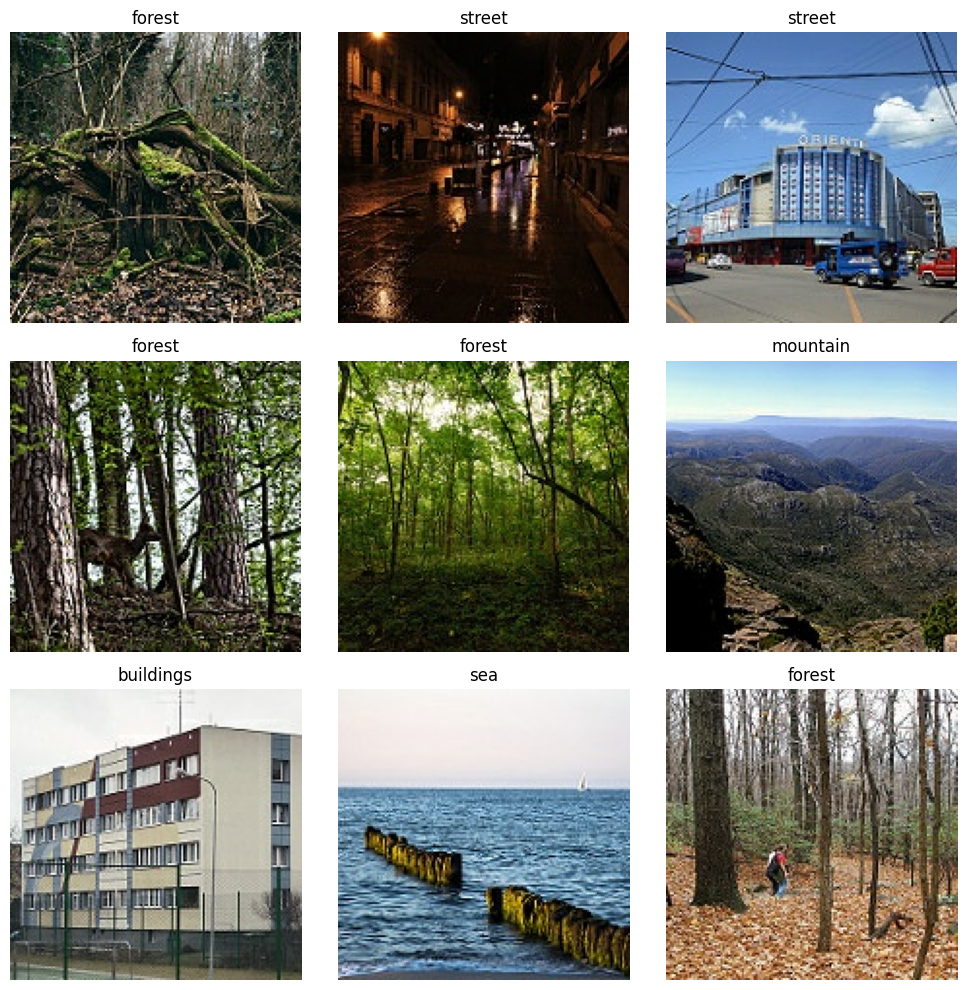

In [8]:
# Display the first 9 images and their labels

images, labels = next(iter(sample_ds))

plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    # Convert the image tensor to an array for plotting
    plt.imshow(images[i].numpy().astype("uint8"))

    # Convert the numerical label to its class name
    plt.title(class_names[int(labels[i].numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

### 2.5 Resize, Normalize, and Split the Dataset

CNNs require consistent input dimensions. We will resize every image to 150 × 150 pixels and use batches of 32 images.

We will then divide the images in `seg_train` into:

- **80% training data:** used to update the model's weights.
- **20% validation data:** used to monitor performance during training and compare model configurations.

The separate `seg_test` directory is never used to update the weights or to decide when to stop training. It is used only to report each model's final test accuracy.

Finally, pixel values will be normalized from the original range of 0–255 to the range 0–1 by dividing by 255.

In [9]:
# Part 2.5: Create training, validation, and test datasets

# Create the training subset: 80% of seg_train
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

# Create the validation subset: 20% of seg_train
# IMPORTANT: keep the same seed AND shuffle=True as the training subset.
# That is what makes the two subsets complementary (no image in both).
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

# Load the separate test dataset (not shuffled, so predictions stay in label order)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Confirm that the class order is consistent
print("Training classes:", train_ds.class_names)
print("Validation classes:", val_ds.class_names)
print("Test classes:", test_ds.class_names)

# Remember which files belong to each dataset.
# These lists exist only on the datasets as created above, so we save them now.
train_files = train_ds.file_paths
val_files = val_ds.file_paths
test_files = test_ds.file_paths

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Training classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Validation classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Test classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [10]:
# Part 2.5 (continued): Normalize the pixels and speed up the input pipeline

AUTOTUNE = tf.data.AUTOTUNE

# Normalize pixel values from [0, 255] to [0, 1]
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

def normalize(images, labels):
    return normalization_layer(images), labels

# cache():    keep the decoded images in memory, so each JPG is read from disk only once
# map():      divide every pixel by 255
# prefetch(): prepare the next batch while the model is training on the current one
train_ds = train_ds.cache()
train_ds = train_ds.map(normalize)
train_ds = train_ds.prefetch(AUTOTUNE)

val_ds = val_ds.cache()
val_ds = val_ds.map(normalize)
val_ds = val_ds.prefetch(AUTOTUNE)

test_ds = test_ds.cache()
test_ds = test_ds.map(normalize)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Caching, normalization and prefetching applied to training, validation, and test datasets.")

Caching, normalization and prefetching applied to training, validation, and test datasets.


**Why normalize all three datasets?**

All datasets must use the same input scale. Only the training dataset is used to learn model parameters; validation and test data are transformed consistently but are not used to update the model's weights.

**Why cache and prefetch, and why in this order?**

- Reading and decoding a JPG is the slowest part of training. Without `cache()`, every epoch reads all the files again. When the dataset is on Google Drive this is so slow that even a GPU spends most of its time waiting for images (about 600 ms per step in our first run).
- With `cache()`, the first epoch is slower while the memory is filled. Every later epoch reuses the images from memory. The three datasets need roughly 4-5 GB of RAM, which fits in a normal Colab session.
- The order is: `cache()` first (so the slow reading is stored), `map()` next (cheap arithmetic), `prefetch()` last (so the model never waits for the next batch).
- One side effect: after the first epoch the training batches contain the same images in every epoch. That is fine for this lab. The random augmentation in Part 5 is not affected because it runs inside the model.
- If your computer runs out of memory, remove the three `cache()` lines. Everything still works, just more slowly.

### 2.6 Report Dataset Sizes

We will now report the dataset sizes and verify the shape and value range of one batch.

Keras keeps the list of files behind each dataset, so we can report the real sample counts straight away without loading any image. We also check that no image appears in both the training and validation sets.

In [11]:
# Part 2.6: Report dataset sizes (read from the file lists, no images are loaded)

num_train = len(train_files)
num_val = len(val_files)
num_test = len(test_files)

print("Training images  :", num_train)
print("Validation images:", num_val)
print("Test images      :", num_test)
print("Number of classes:", len(class_names))

# Safety checks
print("\nTraining + validation equals seg_train:", num_train + num_val == total_train_images)
print("Test equals seg_test:", num_test == total_test_images)
print("Images found in BOTH training and validation:", len(set(train_files) & set(val_files)))

Training images  : 11228
Validation images: 2806
Test images      : 3000
Number of classes: 6

Training + validation equals seg_train: True
Test equals seg_test: True
Images found in BOTH training and validation: 0


In [12]:
# Inspect one normalized batch to verify the input data

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))

Image batch shape: (32, 150, 150, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


You should see image batches with dimensions similar to (32, 150, 150, 3). The last batch may contain fewer than 32 images. Pixel values should be between 0.0 and 1.0.

**What to look for**

- Training / validation / test should be 11228 / 2806 / 3000, with 6 classes.
- The last number must be `0`. If it is not, the validation set contains images the model trains on, and every validation score would be too optimistic.
- Normalizing with a cached dataset may print a warning that "the calling iterator did not fully read the dataset being cached". It appears because we only look at one batch here. It is harmless.

### Understand: Part 2 (tutor questions)

Try to answer these aloud before moving on.

1. The training and validation subsets come from two separate calls. What must be identical in both calls, and what did the "images found in both" check prove?
2. Why is the test set loaded with `shuffle=False`, and why is it never used to make decisions during training?
3. Why are pixel values divided by 255? What would happen if only the training images were scaled?
4. Why does `cache()` come before `map()`, and why is `prefetch()` last?
5. The classes range from 2,191 to 2,512 training images. Is that a problem for using accuracy as the metric?

## Part 3: Building and Training the Baseline CNN

### 3.1 Understanding the Baseline CNN
In this section, we will build our first Convolutional Neural Network (CNN) to classify images into six categories: buildings, forest, glacier, mountain, sea, and street.

A CNN learns visual patterns from images automatically. Early layers can learn simple features such as edges and textures, while deeper layers can learn more complex patterns.

Our baseline model will contain these layers:

1. **Conv2D:** Detects visual features using learnable filters.
2. **MaxPooling2D:** Reduces the spatial dimensions of the feature maps.
3. **Flatten:** Converts the feature maps into a one-dimensional vector.
4. **Dense:** Learns relationships between extracted features.
5. **Output layer:** Produces a score for each of the six classes.

We will train this model first and use its test accuracy as our baseline for comparison with improved CNN models in later sections.

### 3.2 Build the Baseline CNN

We will use `Sequential` to stack the layers in order.

The input image has a shape of **150 × 150 × 3**: height, width, and three colour channels (red, green, and blue).

We will use ReLU activation in the hidden layers and softmax in the output layer. Softmax produces a probability distribution across the six classes.

The model will use the Adam optimizer and sparse categorical cross-entropy loss. This loss function is appropriate because our class labels are represented by integers rather than one-hot encoded vectors.

In [13]:
# Part 3.2: Build the baseline CNN

# Start from the same random numbers every time, so a run can be repeated
tf.keras.utils.set_random_seed(SEED)

# Define the baseline CNN architecture
baseline_model = tf.keras.Sequential([
    # Input: 150 x 150 RGB image
    tf.keras.layers.Input(shape=(150, 150, 3)),

    # Convolutional layer: learn visual features
    tf.keras.layers.Conv2D(
        32, kernel_size=(3, 3), activation="relu"
    ),

    # Reduce the spatial dimensions
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Convert feature maps into a one-dimensional vector
    tf.keras.layers.Flatten(),

    # Fully connected layer for classification
    tf.keras.layers.Dense(128, activation="relu"),

    # Output probabilities for the six classes
    tf.keras.layers.Dense(6, activation="softmax")
])

# Configure the model for training
baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline CNN created successfully.")

Baseline CNN created successfully.


### 3.3 Inspect the Model Architecture

Before training, we should inspect the model's structure and the number of parameters.

- **Output Shape** shows the shape of the data after each layer.
- **Param #** shows the number of learnable parameters in each layer.
- **Total params** is the total number of parameters in the model.
- **Trainable params** are parameters that can be updated during training.

This helps us understand the model's complexity and provides information for the report.

In [14]:
# Part 3.3: Display the baseline CNN architecture

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 175232)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    22,429,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,431,494 (85.57 MB)

 Trainable params: 22,431,494 (85.57 MB)

 Non-trainable params: 0 (0.00 B)

Pay attention to the parameter count in the `Flatten` and first `Dense` layers. Flattening feature maps can create a large vector, resulting in many trainable parameters.

### 3.4 Train the Baseline CNN

During training, the model makes predictions, calculates the loss, and updates its weights to improve classification performance.

We will train for **10 epochs** initially and evaluate the model on the validation dataset after each epoch.

An epoch is one complete pass through the training dataset. The validation dataset helps us monitor how well the model performs on images that are not used to update its weights.

We will save the training history so that we can plot accuracy and loss later.

The first epoch is slower because the cache is being filled (Part 2.5). Later epochs should be much faster. With a T4 GPU, expect roughly 10-30 seconds per epoch afterwards.

In [15]:
# Part 3.4: Train the baseline CNN

EPOCHS = 10

history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 23s 49ms/step - accuracy: 0.6540 - loss: 1.0162 - val_accuracy: 0.6326 - val_loss: 0.9872
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8305 - loss: 0.4994 - val_accuracy: 0.6825 - val_loss: 0.9663
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9012 - loss: 0.2965 - val_accuracy: 0.7010 - val_loss: 1.0189
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.9441 - loss: 0.1834 - val_accuracy: 0.7142 - val_loss: 1.0868
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9648 - loss: 0.1375 - val_accuracy: 0.6946 - val_loss: 1.3390
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9767 - loss: 0.0888 - val_accuracy: 0.7017 - val_loss: 1.4178
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9816 - loss: 0.0681 - val_accuracy: 0.6989 - val_loss: 1.6012
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9902 - loss: 0.0419 - val_ac

### 3.5 Evaluate the Baseline CNN

After training, we will evaluate the model on `test_ds`.

The test dataset is separate from the training and validation datasets. Its accuracy gives us an estimate of how well the baseline model classifies previously unseen images.

We will record the test loss and test accuracy. Later, we will compare these results with the improved CNN models.

In [16]:
# Part 3.5: Evaluate the baseline CNN on the test dataset

baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Baseline Test Loss: {baseline_test_loss:.4f}")
print(f"Baseline Test Accuracy: {baseline_test_accuracy:.4f}")
print(f"Baseline Test Accuracy: {baseline_test_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 62ms/step - accuracy: 0.7123 - loss: 1.7902
Baseline Test Loss: 1.7902
Baseline Test Accuracy: 0.7123
Baseline Test Accuracy: 71.23%


### 3.6 Visualise Training Performance

Accuracy and loss curves help us understand how the model learns over time.

- **Training accuracy** measures performance on the training images.
- **Validation accuracy** measures performance on the validation images.
- **Training loss** indicates prediction error on the training data.
- **Validation loss** indicates prediction error on the validation data.

If training accuracy continues to improve while validation performance stagnates or worsens, the model may be overfitting.

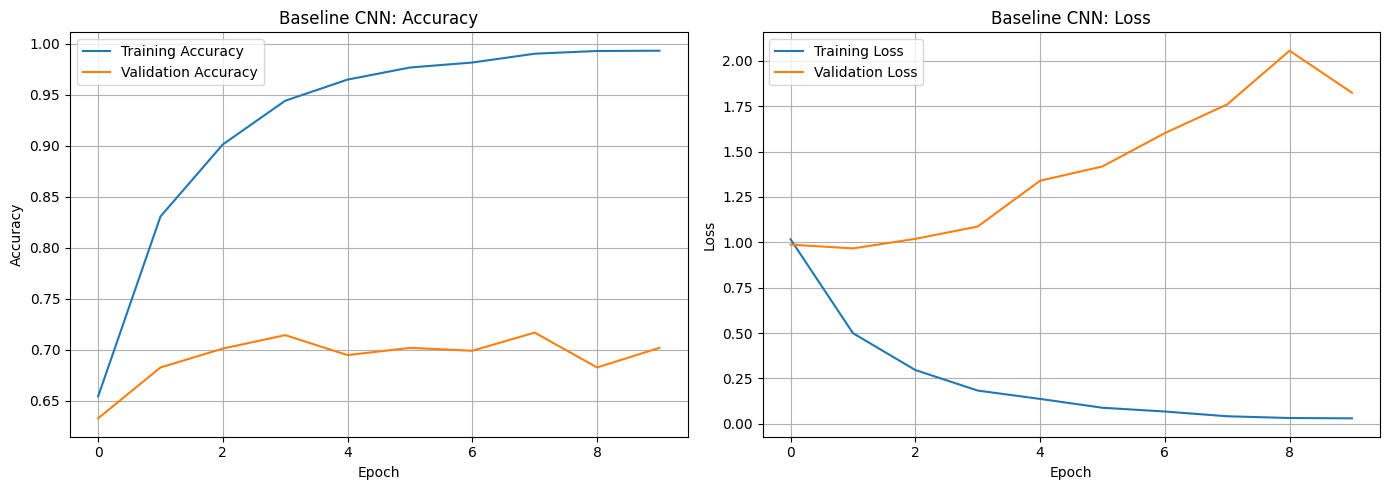

In [17]:
# Part 3.6: Plot training and validation accuracy and loss

# We will plot the same two graphs for several models, so we put the code in a function
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy
    axes[0].plot(history.history["accuracy"], label="Training Accuracy")
    axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
    axes[0].set_title(title + ": Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True)

    # Loss
    axes[1].plot(history.history["loss"], label="Training Loss")
    axes[1].plot(history.history["val_loss"], label="Validation Loss")
    axes[1].set_title(title + ": Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

plot_history(history_baseline, "Baseline CNN")

**What to look for**

- Training accuracy rising while validation accuracy flattens or drops means the model is memorizing the training images (overfitting).
- If validation loss starts rising while training loss keeps falling, that is the same warning in a different form.

### Understand: Part 3 (tutor questions)

1. Where are most of the 22.4 million parameters, and why does `Flatten` cause that? (Hint: 175,232 values are connected to 128 neurons.)
2. Compare your first-epoch training loss with 1.79 (ln 6, the loss of random guessing among 6 classes). What does a much higher value tell you?
3. Do the training and validation curves separate? What is that gap called, and what does it say about this baseline?
4. Why does the last layer use softmax together with `sparse_categorical_crossentropy`? What would change if the labels were one-hot vectors?
5. Why does `Conv2D(32, (3, 3))` turn a 150 x 150 image into 148 x 148 x 32, and `MaxPooling2D` then into 74 x 74 x 32?

## Part 4: Improving the CNN Architecture
### 4.1 Why Modify the CNN?
The baseline CNN used one convolutional layer followed by max pooling, flattening, and dense layers.

However, images contain visual features at different levels of complexity. A deeper CNN can learn more varied features by applying multiple convolutional layers.

In this section, we will build a modified CNN with:

- **More convolutional layers** to learn richer visual features.
- **Multiple max-pooling layers** to reduce the spatial dimensions of feature maps.
- **A much shorter flattened vector:** the extra pooling shrinks the feature map before `Flatten`, so the dense layer needs far fewer weights than in the baseline.
- **A six-unit softmax output layer** to predict the image class.

We will train the modified CNN and compare its test accuracy with the baseline CNN.

### 4.2 Build the Modified CNN

The modified CNN will use three convolutional blocks. Each block contains a convolutional layer with ReLU activation, followed by max pooling.

The number of filters increases from 32 to 64 to 128. This allows deeper layers to learn a larger variety of visual patterns.

We will use `Flatten` and a dense layer to classify the extracted features. Dropout and data augmentation will be explored separately in later parts so that we can study their effects.

In [18]:
# Part 4.2: Build the modified CNN

# Start from the same random numbers every time, so a run can be repeated
tf.keras.utils.set_random_seed(SEED)

modified_model = tf.keras.Sequential([
    # Input image: 150 x 150 RGB
    tf.keras.layers.Input(shape=(150, 150, 3)),

    # Convolutional block 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten feature maps
    tf.keras.layers.Flatten(),

    # Classification layer
    tf.keras.layers.Dense(128, activation="relu"),

    # Output probabilities for six classes
    tf.keras.layers.Dense(6, activation="softmax")
])

# Compile the model using the same settings as the baseline
modified_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modified CNN created successfully.")

Modified CNN created successfully.


### 4.3 Inspect the Modified Architecture

We will inspect the model summary to understand how the additional convolutional layers change the architecture and parameter count.

Compare this summary with the baseline model summary from Part 3.

Consider these questions:

- How many convolutional layers does each model have?
- How do the output shapes change after each pooling layer?
- Which model has more trainable parameters?
- How might additional convolutional layers help the model classify images?

In [19]:
# Part 4.3: Display the modified CNN architecture

modified_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

### 4.4 Train the Modified CNN

We will train the modified CNN using the same training and validation datasets as the baseline.

Using the same number of epochs and the same optimizer and loss function makes it easier to compare the two architectures. However, training time may increase because the modified model has more layers and computations.

In [20]:
# Part 4.4: Train the modified CNN

history_modified = modified_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 24s 49ms/step - accuracy: 0.6240 - loss: 0.9634 - val_accuracy: 0.6411 - val_loss: 0.9556
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.7667 - loss: 0.6323 - val_accuracy: 0.6593 - val_loss: 0.8322
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.8287 - loss: 0.4775 - val_accuracy: 0.7477 - val_loss: 0.7575
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8761 - loss: 0.3514 - val_accuracy: 0.7520 - val_loss: 0.7768
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9043 - loss: 0.2685 - val_accuracy: 0.7548 - val_loss: 0.8229
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9181 - loss: 0.2294 - val_accuracy: 0.7773 - val_loss: 0.8486
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9501 - loss: 0.1556 - val_accuracy: 0.7929 - val_loss: 0.9014
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9656 - loss: 0.1016 - 

### 4.5 Evaluate the Modified CNN

After training, we will evaluate the modified CNN on the separate test dataset.

We will record the test loss and accuracy and compare them with the baseline model. A deeper architecture may improve classification performance, but adding layers does not guarantee better results.

In [21]:
# Part 4.5: Evaluate the modified CNN

modified_test_loss, modified_test_accuracy = modified_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Modified CNN Test Loss: {modified_test_loss:.4f}")
print(f"Modified CNN Test Accuracy: {modified_test_accuracy:.4f}")
print(f"Modified CNN Test Accuracy: {modified_test_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7857 - loss: 1.1831
Modified CNN Test Loss: 1.1831
Modified CNN Test Accuracy: 0.7857
Modified CNN Test Accuracy: 78.57%


### 4.6 Compare the Baseline and Modified CNN

We will compare the test accuracy and loss of the two models.

- Higher test accuracy means more test images were classified correctly.
- Lower test loss generally indicates better predictions under the selected loss function.
- The best model should not be selected based on training accuracy alone because a model may perform well on training data but generalize poorly to unseen images.

We will use the comparison as a starting point for the improvements in Parts 5 and 6.

In [22]:
# Part 4.6: Compare model evaluation results

import pandas as pd

comparison_part4 = pd.DataFrame({
    "Model": ["Baseline CNN", "Modified CNN"],
    "Test Loss": [baseline_test_loss, modified_test_loss],
    "Test Accuracy": [
        baseline_test_accuracy,
        modified_test_accuracy
    ]
})

comparison_part4["Test Accuracy (%)"] = (
    comparison_part4["Test Accuracy"] * 100
)

display(comparison_part4)

,Model,Test Loss,Test Accuracy,Test Accuracy (%)
0,Baseline CNN,1.790205,0.712333,71.233332
1,Modified CNN,1.183146,0.785667,78.566664


### 4.7 Compare Training and Validation Curves

Test accuracy gives us a final performance measure, while training and validation curves help explain how each model learned.

We first plot the modified model's own training and validation curves, then the validation accuracy of both models together. If training accuracy is much higher than validation accuracy, the model may be overfitting.

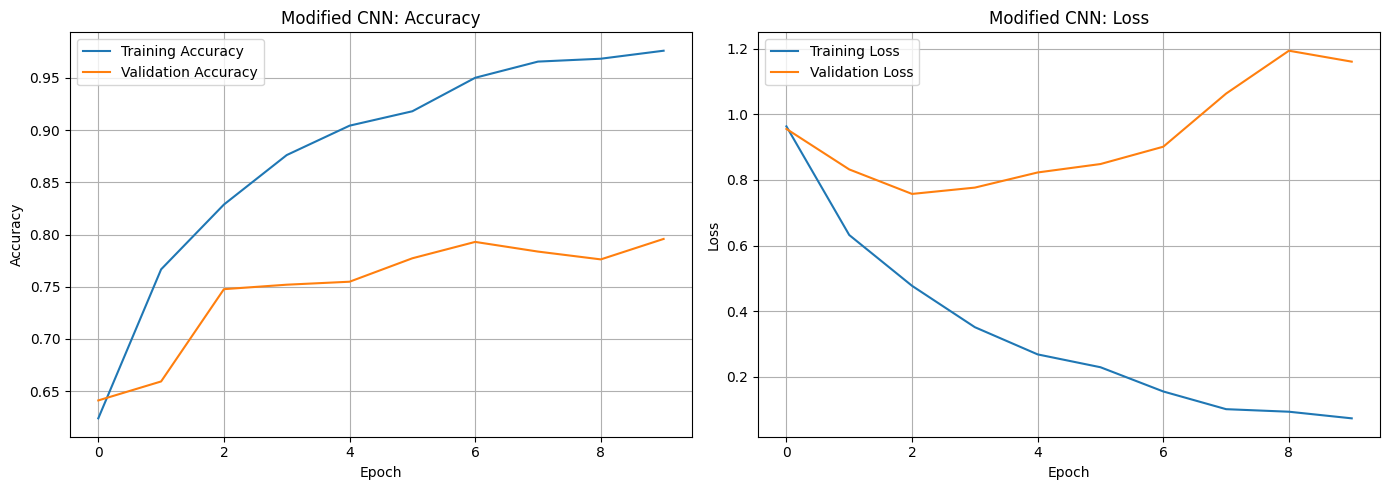

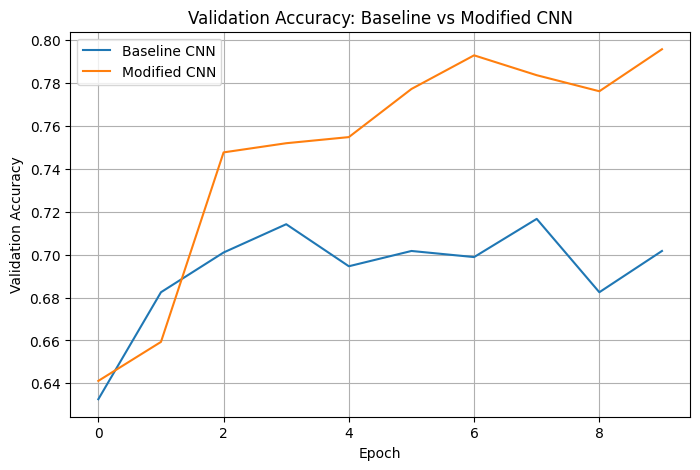

In [23]:
# Part 4.7: Training vs validation curves, then a comparison of the two models

plot_history(history_modified, "Modified CNN")

plt.figure(figsize=(8, 5))

plt.plot(history_baseline.history["val_accuracy"], label="Baseline CNN")
plt.plot(history_modified.history["val_accuracy"], label="Modified CNN")

plt.title("Validation Accuracy: Baseline vs Modified CNN")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Understand: Part 4 (tutor questions)

1. The modified model has more layers but far fewer parameters than the baseline (about 4.8 million against 22.4 million). Why? (Hint: compare the size of the vector after `Flatten`.)
2. What does each extra `Conv2D` + `MaxPooling2D` pair add, and why do the filters grow from 32 to 64 to 128?
3. Did the modified model beat the baseline on the test set? If the difference is about one point, would you trust it? (Hint: each result comes from a single run with random starting weights.)
4. Looking at its curves, does the modified model still overfit? How can you tell?

## Part 5: Data Augmentation
### 5.1 Understanding Data Augmentation

Data augmentation creates varied versions of training images by applying random transformations. Instead of relying only on the original images, the model learns from different variations of those images during training.

For image classification, common transformations include:

- **Random flip:** flips an image horizontally.
- **Random rotation:** rotates an image slightly.
- **Random zoom:** zooms in or out of an image.

Data augmentation can help reduce overfitting by exposing the model to more visual variation. However, it does not guarantee higher accuracy.

**Important:** Augmentation should be applied only to the training data. Validation and test images should remain unchanged apart from the standard resizing and normalization.

### 5.2 Create the Augmentation Layers

TensorFlow provides preprocessing layers that can perform random image transformations during training.

We will use horizontal flipping, a small rotation, and random zoom. These transformations are applied dynamically during training rather than creating additional image files on disk.

When the model is evaluated, these augmentation layers do not randomly transform the images.

In [24]:
# Part 5.2: Define data augmentation

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),   # mirror left-right
    tf.keras.layers.RandomRotation(0.05),       # 0.05 of a full turn = up to 18 degrees either way
    tf.keras.layers.RandomZoom(0.1)             # zoom in or out by up to 10%
], name="data_augmentation")

print("Data augmentation layers created.")

Data augmentation layers created.


### 5.3 Visualise Augmented Images

Before training, we will inspect how augmentation changes the appearance of an image.

The following code selects one image from the training dataset and generates several augmented versions. This helps us verify that the transformations work as expected.

The examples are for visual inspection only; they do not change the original dataset stored on disk.

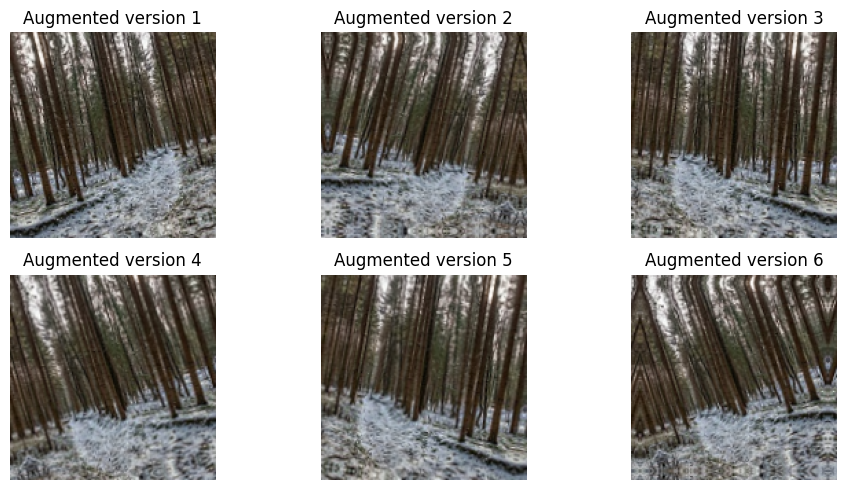

In [25]:
# Part 5.3: Display augmented versions of one training image

# Get one batch of normalized training images
images, labels = next(iter(train_ds))

# Select one image
sample_image = images[0]

plt.figure(figsize=(10, 5))

for i in range(6):
    # Apply random augmentation to the selected image
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )[0]

    plt.subplot(2, 3, i + 1)

    # Display the image
    plt.imshow(tf.clip_by_value(augmented_image, 0, 1).numpy())

    plt.title(f"Augmented version {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 5.4 Build the Augmented CNN

We will now create a CNN that includes the augmentation layers at the beginning of the model.

The remaining architecture will be similar to the modified CNN from Part 4. This helps us investigate whether augmentation improves performance without changing the overall feature-extraction structure.

The augmentation layers operate on training images during training. We will continue using the same normalized training, validation, and test datasets.

In [26]:
# Part 5.4: Build the CNN with data augmentation

# Start from the same random numbers every time, so a run can be repeated
tf.keras.utils.set_random_seed(SEED)

augmented_model = tf.keras.Sequential([
    # Input image
    tf.keras.layers.Input(shape=(150, 150, 3)),

    # Random transformations during training
    data_augmentation,

    # Convolutional block 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(6, activation="softmax")
], name="augmented_cnn")

# Use the same compilation settings as the previous CNNs
augmented_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN created successfully.")
augmented_model.summary()

Augmented CNN created successfully.


Model: "augmented_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

### 5.5 Train the Augmented CNN

We will train the augmented CNN using the same training and validation datasets and the same number of epochs as the previous models.

Augmentation may make training slower because the images undergo random transformations. Training accuracy may also be lower than the model without augmentation because the training images are more varied.

We will use validation performance to observe whether the model generalizes better.

In [27]:
# Part 5.5: Train the augmented CNN

history_augmented = augmented_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 17s 36ms/step - accuracy: 0.6201 - loss: 0.9831 - val_accuracy: 0.6900 - val_loss: 0.8070
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.7285 - loss: 0.7386 - val_accuracy: 0.7153 - val_loss: 0.7091
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.7768 - loss: 0.6134 - val_accuracy: 0.7801 - val_loss: 0.5957
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.8029 - loss: 0.5409 - val_accuracy: 0.7726 - val_loss: 0.5925
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8172 - loss: 0.5055 - val_accuracy: 0.7958 - val_loss: 0.5597
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.8340 - loss: 0.4604 - val_accuracy: 0.7798 - val_loss: 0.6175
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.8442 - loss: 0.4306 - val_accuracy: 0.7637 - val_loss: 0.6677
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.8528 - loss: 0.4001 - 

### 5.6 Evaluate the Augmented CNN

After training, we will evaluate the model on the separate test dataset.

We will record the test loss and test accuracy and compare them with the previous CNN models. This allows us to assess whether data augmentation helped the model classify unseen images.

In [28]:
# Part 5.6: Evaluate the augmented CNN

augmented_test_loss, augmented_test_accuracy = augmented_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Augmented CNN Test Loss: {augmented_test_loss:.4f}")
print(f"Augmented CNN Test Accuracy: {augmented_test_accuracy:.4f}")
print(f"Augmented CNN Test Accuracy: {augmented_test_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7747 - loss: 0.8086
Augmented CNN Test Loss: 0.8086
Augmented CNN Test Accuracy: 0.7747
Augmented CNN Test Accuracy: 77.47%


### 5.7 Compare All Three Models

We will compare the baseline CNN, modified CNN, and augmented CNN using their test accuracy and test loss.

A higher test accuracy indicates that more test images were classified correctly. A lower test loss generally indicates better predictions according to the selected loss function.

Data augmentation is not guaranteed to improve accuracy. We should interpret the results alongside the training and validation curves rather than assuming the newest model must be the best.

In [29]:
# Part 5.7: Compare the three CNN models

comparison_part5 = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Modified CNN",
        "Augmented CNN"
    ],
    "Test Loss": [
        baseline_test_loss,
        modified_test_loss,
        augmented_test_loss
    ],
    "Test Accuracy (%)": [
        baseline_test_accuracy * 100,
        modified_test_accuracy * 100,
        augmented_test_accuracy * 100
    ]
})

display(
    comparison_part5.sort_values(
        by="Test Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Test Loss,Test Accuracy (%)
0,Modified CNN,1.183146,78.566664
1,Augmented CNN,0.808619,77.466667
2,Baseline CNN,1.790205,71.233332


### 5.8 Training and Validation Curves of the Augmented CNN

We plot the augmented model's own curves, in the same way as for the earlier models.

Compare the gap between training and validation accuracy with the gap you saw for the modified CNN. Augmentation is meant to make that gap smaller. Training accuracy may be lower than before because the training images are now harder.

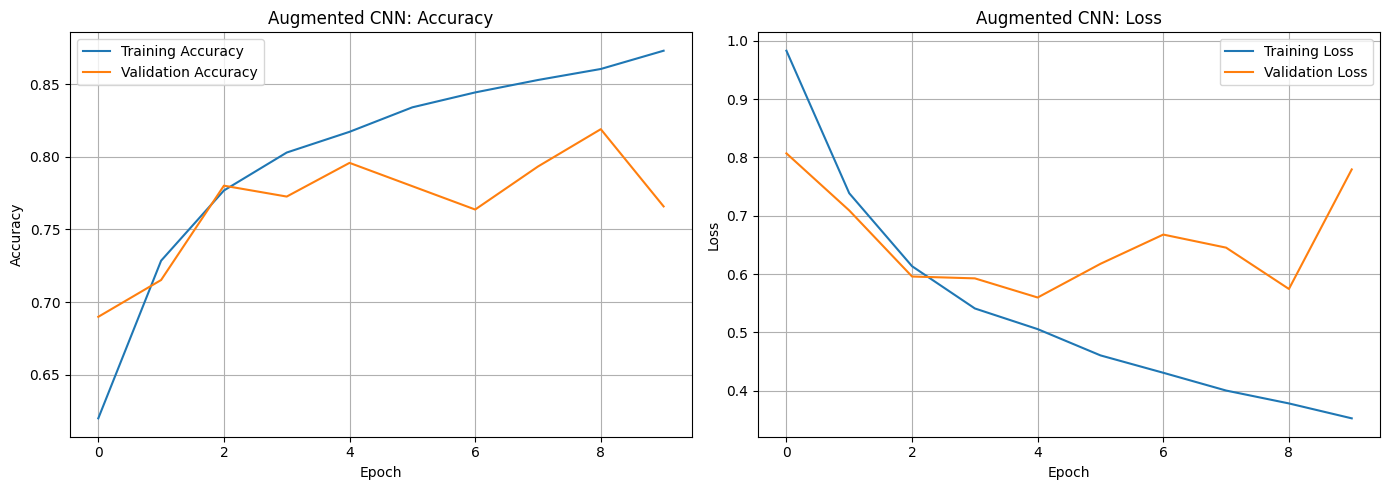

In [30]:
# Part 5.8: Training vs validation curves of the augmented CNN

plot_history(history_augmented, "Augmented CNN")

### Understand: Part 5 (tutor questions)

1. Why is augmentation applied only to training data? Where in the model are the augmentation layers, and why do they do nothing during `evaluate()`?
2. `RandomRotation(0.05)` rotates by up to how many degrees? Why is a vertical flip not used for these scene photos?
3. The augmented model's training accuracy is often lower than the unaugmented one. Is that a problem?
4. Which curves tell you whether augmentation reduced overfitting?
5. Brightness is another common augmentation. Why can heavy zoom or rotation sometimes hurt for scene images?

## Part 6: Regularization and Overfitting Control

### 6.1 Understanding Regularization
A CNN may achieve high accuracy on training images but perform less effectively on unseen images. This problem is known as **overfitting**.

Regularization techniques help reduce overfitting and improve generalization.

In this section, we will explore two techniques:

- **Dropout:** Randomly deactivates a proportion of neurons during training, reducing the model's reliance on particular neurons.
- **EarlyStopping:** Monitors validation loss and stops training when the model stops improving for a specified number of epochs.

We will build a regularized CNN, train it, and compare its performance with the previous models.

Neither technique guarantees better accuracy, so we will evaluate the results rather than assume an improvement.

### 6.2 Build the Regularized CNN

We will use the modified CNN architecture from Part 4 and add a Dropout layer after the dense hidden layer.

A dropout rate of 0.5 means that approximately half of the activations in that layer are randomly set to zero during training. Dropout is disabled during evaluation and prediction.

For this experiment, we will not include data augmentation. This allows us to investigate a model with Dropout and EarlyStopping separately from the augmented model in Part 5.

In [31]:
# Part 6.2: Build the regularized CNN

# Start from the same random numbers every time, so a run can be repeated
tf.keras.utils.set_random_seed(SEED)

regularized_model = tf.keras.Sequential([
    # Input image
    tf.keras.layers.Input(shape=(150, 150, 3)),

    # Convolutional block 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    tf.keras.layers.Flatten(),

    # Fully connected hidden layer
    tf.keras.layers.Dense(128, activation="relu"),

    # Dropout regularization
    tf.keras.layers.Dropout(0.5),

    # Output layer: six classes
    tf.keras.layers.Dense(6, activation="softmax")
], name="regularized_cnn")

# Compile the model
regularized_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Regularized CNN created successfully.")
regularized_model.summary()

Regularized CNN created successfully.


Model: "regularized_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

### 6.3 Configure EarlyStopping

We will use the `EarlyStopping` callback to monitor validation loss.

The settings are:

- `monitor="val_loss"`: monitor the loss on validation data.
- `patience=3`: stop if validation loss fails to improve for three consecutive epochs.
- `restore_best_weights=True`: restore the weights from the epoch with the lowest validation loss.

EarlyStopping can stop training before the maximum number of epochs is reached. This may save time and help avoid continuing to train after validation performance has stopped improving.

In [32]:
# Part 6.3: Configure EarlyStopping

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("EarlyStopping callback created.")

EarlyStopping callback created.


### 6.4 Train the Regularized CNN

We will train the regularized CNN using the same training and validation datasets.

We will allow up to 15 epochs, but EarlyStopping may stop training earlier if validation loss does not improve for three consecutive epochs.

The training history will be saved so that we can examine the learning curves.

In [33]:
# Part 6.4: Train the regularized CNN

history_regularized = regularized_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.5881 - loss: 1.0616 - val_accuracy: 0.6639 - val_loss: 0.9712
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.7286 - loss: 0.7528 - val_accuracy: 0.7028 - val_loss: 0.8172
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.7783 - loss: 0.6268 - val_accuracy: 0.7855 - val_loss: 0.6124
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8122 - loss: 0.5379 - val_accuracy: 0.8072 - val_loss: 0.5469
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8356 - loss: 0.4631 - val_accuracy: 0.8015 - val_loss: 0.5782
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8605 - loss: 0.3872 - val_accuracy: 0.8204 - val_loss: 0.5922
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8828 - loss: 0.3301 - val_accuracy: 0.8229 - val_loss: 0.6157
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 4.


### 6.5 Evaluate the Regularized CNN

After training, we will evaluate the regularized model on the separate test dataset.

We will record the test loss and test accuracy. Because the best validation-loss weights are restored by EarlyStopping, the evaluation uses those restored weights.

We will compare these results with the baseline, modified, and augmented CNNs.

In [34]:
# Part 6.5: Evaluate the regularized CNN

regularized_test_loss, regularized_test_accuracy = (
    regularized_model.evaluate(test_ds, verbose=1)
)

print(f"Regularized CNN Test Loss: {regularized_test_loss:.4f}")
print(
    f"Regularized CNN Test Accuracy: "
    f"{regularized_test_accuracy * 100:.2f}%"
)

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8137 - loss: 0.5532
Regularized CNN Test Loss: 0.5532
Regularized CNN Test Accuracy: 81.37%


### 6.6 Visualise Training and Validation Curves

We will plot the training and validation loss to examine the model's learning behaviour.

If training loss continues to decrease while validation loss increases, this may indicate overfitting. If both losses remain high, the model may be underfitting or may need further tuning.

Dropout does not guarantee that the training loss will be lower. Its purpose is to regularize learning and potentially improve generalization.

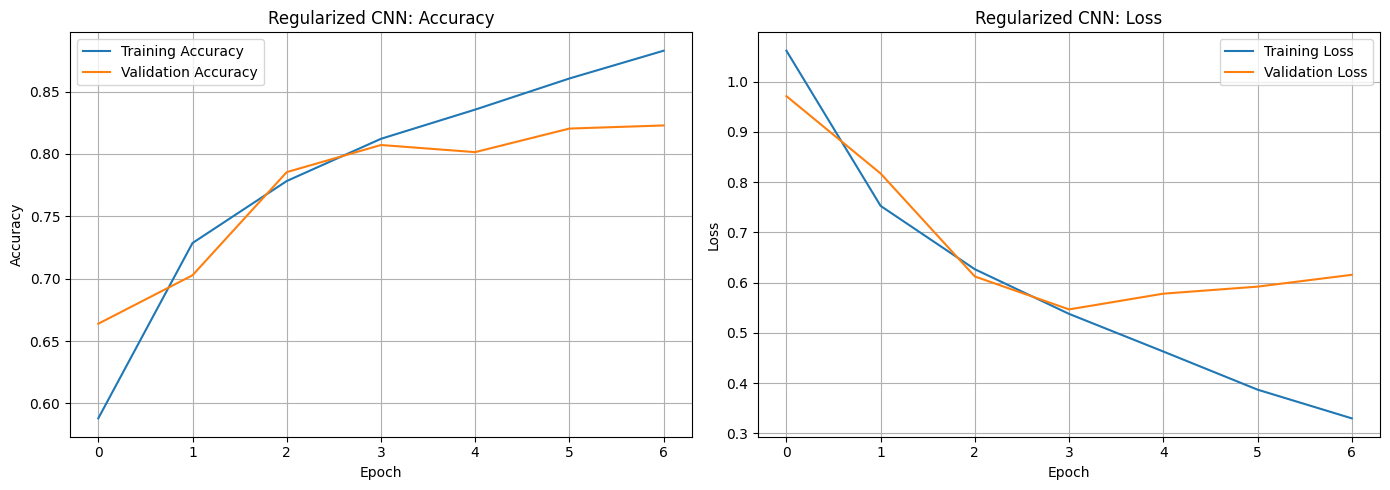

In [35]:
# Part 6.6: Training vs validation curves of the regularized CNN

plot_history(history_regularized, "Regularized CNN")

### 6.7 Extra: Combine Augmentation, Dropout and EarlyStopping

Tasks 4 and 5 each changed one thing at a time, so we can see what each technique does on its own. The lab asks us to report those tasks separately, so they stay exactly as they are.

As an extra, we now combine all three techniques to see whether they work together. This model is **not** one of Tasks 2-5, so label it as an extra in the report.

We allow up to 30 epochs and use `patience=5`, because augmented training improves more slowly. EarlyStopping ends training sooner if the validation loss stops improving.

In [36]:
# Part 6.7: Build the combined model (augmentation + Dropout)

# Start from the same random numbers every time, so a run can be repeated
tf.keras.utils.set_random_seed(SEED)

combined_model = tf.keras.Sequential([
    # Input image
    tf.keras.layers.Input(shape=(150, 150, 3)),

    # Random transformations (training only)
    data_augmentation,

    # Convolutional block 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers with Dropout
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(6, activation="softmax")
], name="combined_cnn")

combined_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

combined_model.summary()

Model: "combined_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

### 6.8 Train and Evaluate the Combined Model

The combined model has its own EarlyStopping callback because its patience is different (5 instead of 3).

In [37]:
# Part 6.8: Train the combined model

combined_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history_combined = combined_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[combined_early_stopping]
)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.5674 - loss: 1.1244 - val_accuracy: 0.6183 - val_loss: 1.0245
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.6910 - loss: 0.8558 - val_accuracy: 0.7555 - val_loss: 0.6645
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.7305 - loss: 0.7510 - val_accuracy: 0.7830 - val_loss: 0.5881
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.7502 - loss: 0.6900 - val_accuracy: 0.7876 - val_loss: 0.5740
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.7800 - loss: 0.6336 - val_accuracy: 0.7762 - val_loss: 0.5958
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.7851 - loss: 0.5989 - val_accuracy: 0.7748 - val_loss: 0.6012
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.7937 - loss: 0.5735 - val_accuracy: 0.7780 - val_loss: 0.5953
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8034 - loss: 0.5443 - 

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8340 - loss: 0.5159
Combined CNN Test Loss: 0.5159
Combined CNN Test Accuracy: 83.40%


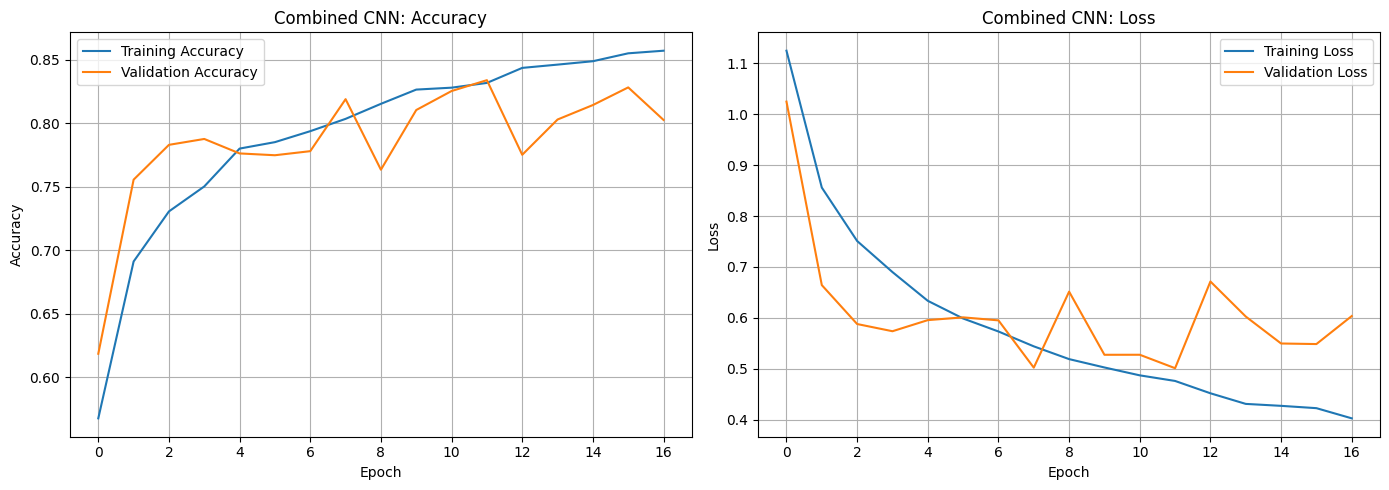

In [38]:
# Part 6.8 (continued): Evaluate the combined model on the test dataset

combined_test_loss, combined_test_accuracy = combined_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Combined CNN Test Loss: {combined_test_loss:.4f}")
print(f"Combined CNN Test Accuracy: {combined_test_accuracy * 100:.2f}%")

plot_history(history_combined, "Combined CNN")

### Understand: Part 6 (tutor questions)

1. How does `Dropout(0.5)` work during training, and what happens to it at test time?
2. Why does EarlyStopping monitor `val_loss`? What does `restore_best_weights=True` do, and what does `patience` control?
3. Task 5 differs from Task 3 in three ways: Dropout, EarlyStopping, and up to 15 instead of 10 epochs. What can and cannot be concluded about each technique from one comparison?
4. If the combined model is not better than the best single technique, what might explain that?

## Part 7: Final Model Comparison and Visualisation
### 7.1 Introduction
In the previous sections, we trained and evaluated five CNN models:

1. Baseline CNN (Task 2)
2. Modified CNN (Task 3)
3. CNN with Data Augmentation (Task 4)
4. CNN with Regularization (Task 5)
5. Extra: Augmentation + Regularization combined

In this section, we will compare their test accuracy and loss, visualise their performance, and identify a candidate model.

We will consider both performance and generalisation. A model with higher training accuracy is not necessarily better if its validation performance is poor.

For a rigorous evaluation, model selection should primarily use validation results. The test dataset should ideally be reserved for the final evaluation of the selected model.

### 7.2 Create the Final Comparison Table

We will collect the results of all models into one table, in the order they were trained: the number of parameters, how many epochs were run (EarlyStopping may stop early), validation accuracy, test accuracy and test loss.

The results depend on the actual training run, so we will use the values produced by our notebook rather than assuming one model performs best. The validation accuracy is measured with the same weights that were used for the test results.

In [39]:
# Part 7.2: Compare all trained models

# Keep each model and its training history together, in the order they were trained
models = {
    "Baseline CNN": baseline_model,
    "Modified CNN": modified_model,
    "CNN with Data Augmentation": augmented_model,
    "CNN with Regularization": regularized_model,
    "Extra: Augmentation + Regularization": combined_model,
}

histories = {
    "Baseline CNN": history_baseline,
    "Modified CNN": history_modified,
    "CNN with Data Augmentation": history_augmented,
    "CNN with Regularization": history_regularized,
    "Extra: Augmentation + Regularization": history_combined,
}

# Test results recorded earlier: (loss, accuracy)
test_results = {
    "Baseline CNN": (baseline_test_loss, baseline_test_accuracy),
    "Modified CNN": (modified_test_loss, modified_test_accuracy),
    "CNN with Data Augmentation": (augmented_test_loss, augmented_test_accuracy),
    "CNN with Regularization": (regularized_test_loss, regularized_test_accuracy),
    "Extra: Augmentation + Regularization": (combined_test_loss, combined_test_accuracy),
}

# Build one row of the table for each model
rows = []
for name, model in models.items():
    val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
    test_loss, test_accuracy = test_results[name]

    rows.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Epochs run": len(histories[name].history["loss"]),
        "Validation Accuracy (%)": val_accuracy * 100,
        "Test Accuracy (%)": test_accuracy * 100,
        "Test Loss": test_loss,
    })

final_comparison = pd.DataFrame(rows)

display(final_comparison.round({
    "Validation Accuracy (%)": 2,
    "Test Accuracy (%)": 2,
    "Test Loss": 4,
}))

,Model,Parameters,Epochs run,Validation Accuracy (%),Test Accuracy (%),Test Loss
0,Baseline CNN,22431494,10,70.17,71.23,1.7902
1,Modified CNN,4829126,10,79.58,78.57,1.1831
2,CNN with Data Augmentation,4829126,10,76.59,77.47,0.8086
3,CNN with Regularization,4829126,7,80.72,81.37,0.5532
4,Extra: Augmentation + Regularization,4829126,17,83.39,83.40,0.5159


### 7.3 Visualise Test Accuracy

A bar chart provides a quick visual comparison of the recorded test accuracy of each model.

This helps communicate the results clearly in the lab report. We will display accuracy as a percentage so the differences are easier to interpret.

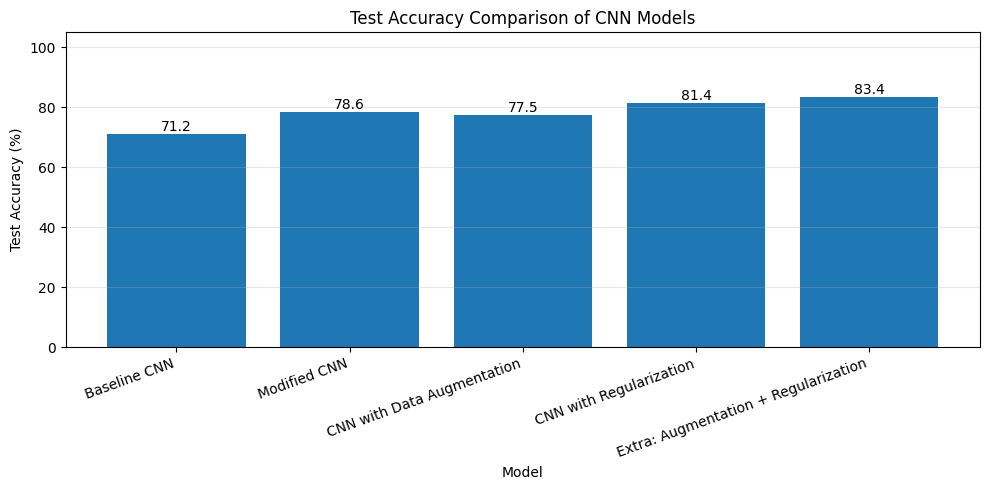

In [40]:
# Part 7.3: Plot test accuracy for all models

# A folder for the figures we will use in the report
os.makedirs("report_figures", exist_ok=True)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    final_comparison["Model"],
    final_comparison["Test Accuracy (%)"]
)
plt.bar_label(bars, fmt="%.1f")   # write the value on top of each bar

plt.title("Test Accuracy Comparison of CNN Models")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("report_figures/test_accuracy.png", dpi=150)
plt.show()

### 7.4 Compare Validation Accuracy

Test accuracy summarises the final evaluation, while validation accuracy helps us compare models during development.

We will plot the validation accuracy curves for all models. These curves show how each model performed on validation images over successive epochs.

Look for models whose validation accuracy improves steadily and then stabilises. A large gap between training and validation accuracy may suggest overfitting.

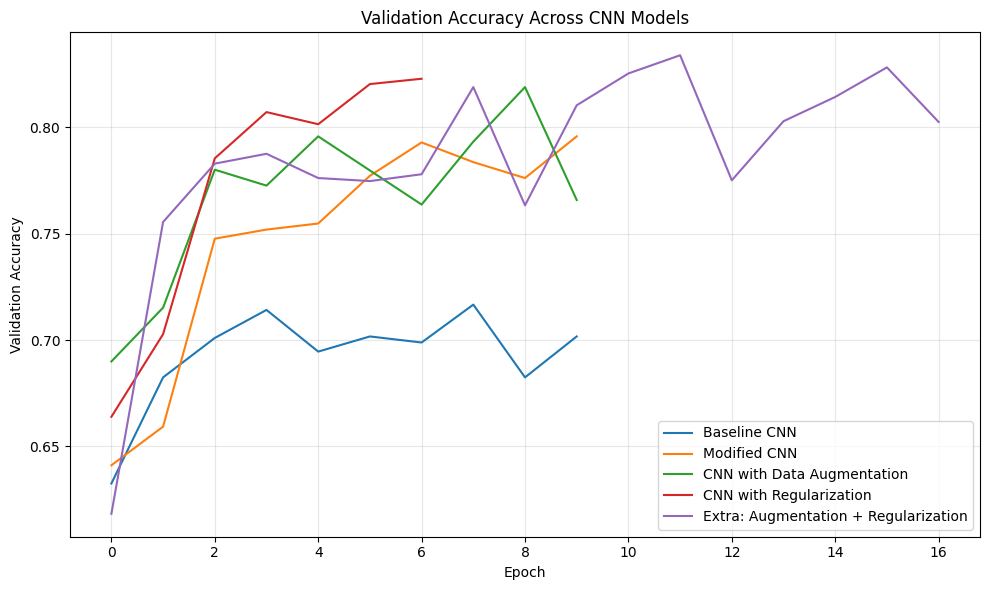

In [41]:
# Part 7.4: Plot validation accuracy across all models

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history.history["val_accuracy"], label=name)

plt.title("Validation Accuracy Across CNN Models")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("report_figures/validation_accuracy.png", dpi=150)
plt.show()

### 7.5 Compare Validation Loss

Validation loss helps us understand how well a model's predictions fit the validation labels.

A decreasing validation loss generally indicates improving predictions. If validation loss begins increasing while training loss continues decreasing, the model may be overfitting.

We will compare the validation loss curves of all models to complement the accuracy comparison.

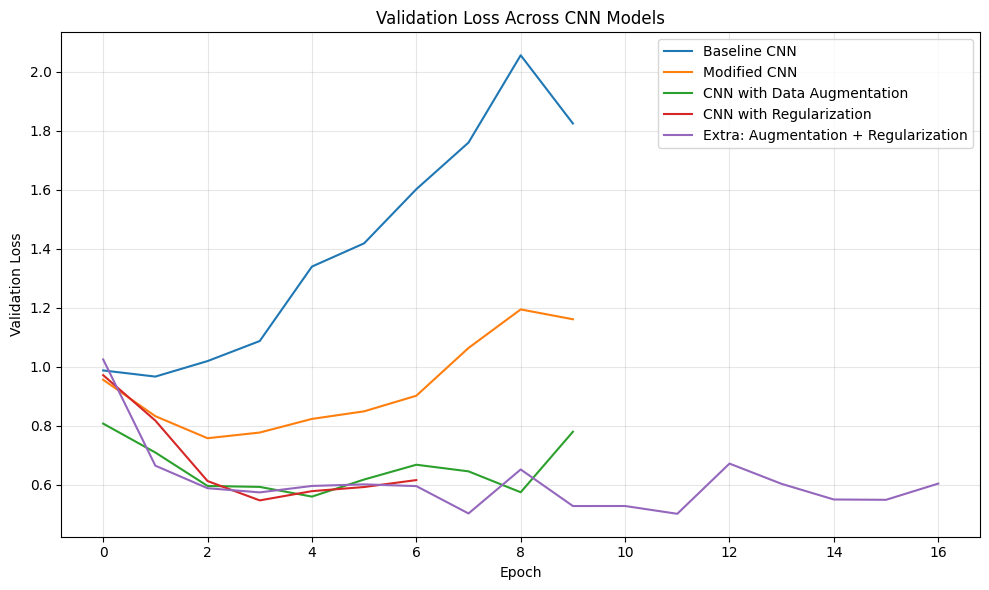

In [42]:
# Part 7.5: Plot validation loss across all models

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history.history["val_loss"], label=name)

plt.title("Validation Loss Across CNN Models")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("report_figures/validation_loss.png", dpi=150)
plt.show()

### 7.6 Identify a Candidate Model

We choose the candidate model using **validation accuracy**, because the validation set exists for making decisions. The test set is then used only to report how that model performs on unseen images.

We also print the model with the highest test accuracy. If the two differ, report both honestly. Because the test set has already been used to compare models in this lab, a test accuracy should be read as a comparison result rather than an unbiased final estimate. A difference of about one percentage point between two models can also be random noise, since every result comes from a single training run.

In [43]:
# Part 7.6: Choose the candidate model by validation accuracy

best_by_validation = final_comparison.sort_values(
    by="Validation Accuracy (%)",
    ascending=False
).iloc[0]

best_by_test = final_comparison.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).iloc[0]

best_name = best_by_validation["Model"]

print("Candidate (highest validation accuracy):", best_name)
print(f"  Validation accuracy: {best_by_validation['Validation Accuracy (%)']:.2f}%")
print(f"  Test accuracy      : {best_by_validation['Test Accuracy (%)']:.2f}%")
print()
print("Highest test accuracy:", best_by_test["Model"])
print(f"  Test accuracy      : {best_by_test['Test Accuracy (%)']:.2f}%")

Candidate (highest validation accuracy): Extra: Augmentation + Regularization
  Validation accuracy: 83.39%
  Test accuracy      : 83.40%

Highest test accuracy: Extra: Augmentation + Regularization
  Test accuracy      : 83.40%


### 7.7 Where Does the Candidate Model Make Mistakes?

Test accuracy is one number. A confusion matrix shows which classes the model mixes up. Each row is the true class and each column is the predicted class, so the diagonal holds the correct predictions.

The test set is not shuffled, so the predictions line up with the true labels.

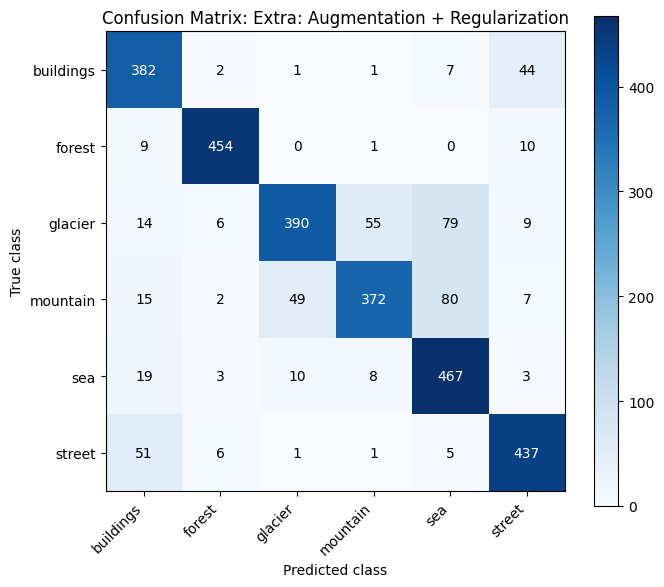

Accuracy per class:
  buildings: 87.4%
  forest: 95.8%
  glacier: 70.5%
  mountain: 70.9%
  sea: 91.6%
  street: 87.2%


In [44]:
# Part 7.7: Confusion matrix of the candidate model on the test set

best_model = models[best_name]

# Predicted class for every test image
probabilities = best_model.predict(test_ds, verbose=0)
predicted = np.argmax(probabilities, axis=1)

# True class for every test image
true_labels = np.concatenate([labels.numpy() for images, labels in test_ds])

# Count how often each (true, predicted) pair happens
confusion = tf.math.confusion_matrix(
    true_labels, predicted, num_classes=len(class_names)
).numpy()

plt.figure(figsize=(7, 6))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

# Write the count inside each square
for i in range(len(class_names)):
    for j in range(len(class_names)):
        colour = "white" if confusion[i, j] > confusion.max() / 2 else "black"
        plt.text(j, i, confusion[i, j], ha="center", va="center", color=colour)

plt.title("Confusion Matrix: " + best_name)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.savefig("report_figures/confusion_matrix.png", dpi=150)
plt.show()

# Accuracy of each class: correct predictions divided by all images of that class
print("Accuracy per class:")
for i, name in enumerate(class_names):
    print(f"  {name}: {confusion[i, i] / confusion[i].sum() * 100:.1f}%")

### Understand: Part 7 (tutor questions)

1. Why do we choose the candidate model by validation accuracy and use the test set only to report?
2. Which two classes are confused most in the matrix? Why might those scenes look alike to a CNN?
3. Compare the parameter counts with the accuracies. Does a bigger model mean a better model here?
4. Every number comes from one run. How could you measure how much of a small difference is just noise? (Hint: repeat with different seeds.)

## Part 8: Conclusion and Lab Report Preparation
### 8.1 Conclusion
In this lab, we applied the machine learning workflow to an image classification problem using the Intel Image Classification dataset.

We prepared the image data, built CNN models, trained and evaluated them, and investigated techniques intended to improve generalisation.

The experiments covered:

- **Baseline CNN:** established a reference performance.
- **Modified CNN:** investigated the effect of adding convolutional layers.
- **Data augmentation:** introduced random image transformations during training.
- **Regularization:** applied Dropout and EarlyStopping to help control overfitting.
- **Extra:** combined augmentation, Dropout and EarlyStopping in one model.

The results allow us to compare the models and discuss how architecture, augmentation, and regularization affected classification performance.

The final conclusion should be based on the actual experimental results rather than assuming that a more complex model always performs better.

### 8.2 Training Settings and Architecture Diagrams

The report must list the training settings and show the architecture of the models. The first cell below prints the settings as a table you can copy into the report. The second cell saves an architecture diagram of each model as an image.

In [45]:
# Part 8.2: Training settings for the report

settings = pd.DataFrame({
    "Setting": [
        "Image size", "Batch size", "Training / validation split",
        "Optimizer", "Loss function",
        "Epochs (Tasks 2-4)", "Data augmentation (Task 4)",
        "Dropout (Task 5)", "EarlyStopping (Task 5)", "Epochs (Task 5, maximum)",
        "Extra model: techniques", "Extra model: EarlyStopping", "Extra model: epochs (maximum)",
    ],
    "Value": [
        "150 x 150 x 3", str(BATCH_SIZE), "80% / 20% of seg_train",
        "Adam (default learning rate 0.001)", "Sparse categorical cross-entropy",
        str(EPOCHS), "RandomFlip (horizontal), RandomRotation (0.05), RandomZoom (0.1)",
        "0.5, after the Dense(128) layer",
        "monitor val_loss, patience 3, restore_best_weights=True", "15",
        "Augmentation + Dropout(0.5) + EarlyStopping",
        "monitor val_loss, patience 5, restore_best_weights=True", "30",
    ],
})

display(settings)

,Setting,Value
0,Image size,150 x 150 x 3
1,Batch size,32
2,Training / validation split,80% / 20% of seg_train
3,Optimizer,Adam (default learning rate 0.001)
4,Loss function,Sparse categorical cross-entropy
5,Epochs (Tasks 2-4),10
6,Data augmentation (Task 4),"RandomFlip (horizontal), RandomRotation (0.05)..."
7,Dropout (Task 5),"0.5, after the Dense(128) layer"
8,EarlyStopping (Task 5),"monitor val_loss, patience 3, restore_best_wei..."
9,"Epochs (Task 5, maximum)",15


In [46]:
# Part 8.3: Save an architecture diagram of each model

# plot_model needs the graphviz and pydot packages. Colab has them.
try:
    for number, (name, model) in enumerate(models.items(), start=1):
        tf.keras.utils.plot_model(
            model,
            to_file=f"report_figures/architecture_{number}.png",
            show_shapes=True,
            show_layer_names=False,
            dpi=80
        )
        print(f"Saved architecture_{number}.png for", name)
except Exception as error:
    print("Could not draw the diagrams on this computer:", error)
    print("Use model.summary() from Parts 3-6 as the architecture description instead.")

Saved architecture_1.png for Baseline CNN
Saved architecture_2.png for Modified CNN
Saved architecture_3.png for CNN with Data Augmentation
Saved architecture_4.png for CNN with Regularization
Saved architecture_5.png for Extra: Augmentation + Regularization


### 8.4 Report Checklist

Before submitting the lab, make sure the report includes:

- The dataset and its six image classes.
- Image size and data split.
- A diagram or summary of each CNN architecture.
- Training settings, including epochs, optimizer, and loss function.
- The data augmentation transformations.
- The regularization techniques used.
- A table comparing the test accuracy of the models.
- A brief explanation of the results and possible overfitting.
- A conclusion supported by the experimental evidence.

The figures are saved in the `report_figures` folder. In Google Colab this folder is deleted when the session ends, so download it (and this notebook) before you close Colab.

Submit the source code and report to Canvas, and prepare to demonstrate the work to the tutor according to the lab instructions.